MNMs on House-of-Cards (HoC) landscapes

This notebook reproduces the House-of-Cards panels of Fig. 1 of Li & Zhang, *Multinucleotide mutations expand evolutionary accessibility on rugged adaptive landscapes*, and shows how the results depend on the distribution of genotype fitness.

1. **Analytical results, uniform fitness (Fig. 1c).** $W_{peak}$, $W_1$, $W_2$, $W_{global}$, the mean escape probabilities $E(q_1)$, $E(q_2)$, and the fraction of the fitness gap closed, $G_1$, $G_2$, for $L = 5$–$10$.
2. **Analytical results, other fitness distributions.** The same quantities when genotype fitness is not uniform.
3. **Adaptive walks on a HoC landscape with $L = 9$ (Fig. 1d–f, h, i).** Endpoint fitness, number of accepted mutations, mean step size, number of peaks escaped, and fraction of peaks escapable by MNMs.
4. **The $L = 9$ adaptation metrics under other fitness distributions.**

**Data.** If the environment variable `MNM_DATA` points to the archived data (see `data/README.md`), part 3 uses the original HoC $L = 9$ landscape and the archived adaptive walks, so these panels reproduce the paper. Otherwise a new HoC $L = 9$ landscape is generated and the walks are simulated with `mnm_mutations`; the results then agree with the paper up to sampling noise.

In [1]:
import os, sys, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate

sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))   # source checkout without `pip install -e .`
from mnm_mutations import Landscape, load_table, walk_original

plt.rcParams.update({'font.family': 'serif', 'font.size': 9, 'axes.spines.top': True, 'axes.spines.right': True,
                     'figure.dpi': 110})
CLS = ['snm', 'adj', 'gen']
LAB = {'snm': 'SNM', 'adj': 'adjacent MNM', 'gen': 'general MNM'}
TICK = {'snm': 'SNM', 'adj': 'adjacent\nMNM', 'gen': 'general\nMNM'}
FILL = {'snm': '#E6E6E6', 'adj': '#3F8098', 'gen': '#D92626'}
LS = range(5, 11)

## 1. Analytical results under uniform fitness

Each genotype of a DNA sequence of $L$ sites has fitness $w \sim U(0,1)$, and $3L$ single-mutant neighbours, $9(L-1)$ adjacent-MNM neighbours and $9L(L-1)/2$ general-MNM neighbours.

* A genotype is a peak with probability $p = w^{3L}$.
* It is the global peak with probability $p' = w^{4^L-1}$.
* A peak is escapable by an adjacent MNM with probability $q_1 = 1-w^{9(L-1)}$, and by a general MNM with probability $q_2 = 1-w^{9L(L-1)/2}$.

So the genotypes counted in $W_{peak}$, $W_1$ (peaks inescapable by adjacent MNMs), $W_2$ (peaks inescapable by general MNMs) and $W_{global}$ all have a density proportional to $w^{a}$, with

| quantity | $a$ |
|---|---|
| $W_{peak}$ | $3L$ |
| $W_1$ | $3L + 9(L-1)$ |
| $W_2$ | $3L + 9L(L-1)/2$ |
| $W_{global}$ | $4^L - 1$ |

The expected fitness is therefore $W = (a+1)/(a+2)$, which gives the formulas in the main text:

* $W_{peak} = \frac{3L+1}{3L+2}$, $W_1 = \frac{12L-8}{12L-7}$, $W_2 = \frac{9L^2-3L+2}{9L^2-3L+4}$, $W_{global} = \frac{4^L}{4^L+1}$
* $E(q_1) = \frac{9L-9}{12L-8}$, $E(q_2) = \frac{9L^2-9L}{9L^2-3L+2}$
* $G_k = \frac{W_k - W_{peak}}{W_{global}-W_{peak}}$

In [2]:
def exponents(L):
    # exponent a of w in the density of each class of genotypes (see the table above)
    return {'W_peak': 3 * L, 'W1': 3 * L + 9 * (L - 1), 'W2': 3 * L + 9 * L * (L - 1) // 2, 'W_global': 4 ** L - 1}

rows = []
for L in LS:
    W = {k: (a + 1) / (a + 2) for k, a in exponents(L).items()}
    rows.append(dict(L=L, **W,
                     E_q1=(9 * L - 9) / (12 * L - 8), E_q2=(9 * L**2 - 9 * L) / (9 * L**2 - 3 * L + 2),
                     G1=(W['W1'] - W['W_peak']) / (W['W_global'] - W['W_peak']),
                     G2=(W['W2'] - W['W_peak']) / (W['W_global'] - W['W_peak']),
                     G1_approx=(9 * L - 9) / (12 * L - 7), G2_approx=(9 * L**2 - 9 * L) / (9 * L**2 - 3 * L + 4)))
uniform = pd.DataFrame(rows).set_index('L')
uniform.round(4)

,W_peak,W1,W2,W_global,E_q1,E_q2,G1,G2,G1_approx,G2_approx
L,,,,,,,,,,
5,0.9412,0.9811,0.9907,0.9990,0.6923,0.8491,0.6907,0.8553,0.6792,0.8411
6,0.9500,0.9846,0.9935,0.9998,0.7031,0.8766,0.6957,0.8752,0.6923,0.8710
7,0.9565,0.9870,0.9953,0.9999,0.7105,0.8957,0.7023,0.8928,0.7013,0.8915
8,0.9615,0.9888,0.9964,1.0000,0.7159,0.9097,0.7081,0.9068,0.7079,0.9065
9,0.9655,0.9901,0.9972,1.0000,0.7200,0.9205,0.7130,0.9179,0.7129,0.9178
10,0.9688,0.9912,0.9977,1.0000,0.7232,0.9289,0.7168,0.9268,0.7168,0.9268


The main text gives $G_1 \approx 67.9\%$ and $G_2 \approx 84.1\%$ for $L = 5$; these are the approximations `G1_approx` and `G2_approx`, which take $W_{global} \approx 1$. The exact values are in the columns `G1` and `G2`.

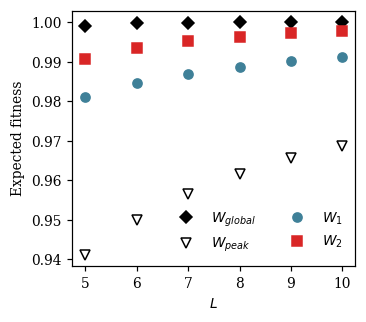

In [3]:
MARK = {'W_global': ('D', 'black', 'black'), 'W_peak': ('v', 'white', 'black'),
        'W1': ('o', '#3F8098', '#3F8098'), 'W2': ('s', '#D92626', '#D92626')}
WLAB = {'W_global': '$W_{global}$', 'W_peak': '$W_{peak}$', 'W1': '$W_1$', 'W2': '$W_2$'}

def plot_fig1c(ax, tab, title=None):
    for k, (m, fc, ec) in MARK.items():
        ax.plot(tab.index, tab[k], m, mfc=fc, mec=ec, ms=6, label=WLAB[k], ls='none')
    ax.set_xlabel('$L$'); ax.set_ylabel('Expected fitness'); ax.set_xticks(list(tab.index))
    if title: ax.set_title(title)

fig, ax = plt.subplots(figsize=(3.4, 3))
plot_fig1c(ax, uniform)
ax.legend(ncol=2, frameon=False, loc='lower right')
plt.tight_layout()

## 2. Analytical results under other fitness distributions

Whether a genotype is a peak, or a peak that MNMs cannot escape, depends only on the **ranks** of the fitness values. So for any continuous fitness distribution with quantile function $Q$, the fitness quantile $V$ of these genotypes has the same density $\propto v^{a}$ as in the uniform case: $V \sim \mathrm{Beta}(a+1, 1)$, and $W = E[Q(V)]$. Writing $V = e^{-t/(a+1)}$ with $t \sim \mathrm{Exp}(1)$,

$$W = \int_0^\infty Q\!\left(e^{-t/(a+1)}\right) e^{-t}\, dt .$$

Two consequences:

* The escape probabilities $E(q_1)$ and $E(q_2)$ do not depend on the fitness distribution.
* $W_{peak}$, $W_1$, $W_2$, $W_{global}$, and therefore $G_1$ and $G_2$, do depend on it. They are computed below for six distributions: Uniform(0,1), three Beta distributions, $\exp(-1/E)$ with $E \sim \mathrm{Exp}(1)$ (bounded, with an exponentially thin upper tail) and Normal(0,1); for each, $G$ measures how much of the gap between the SNM endpoint and the global peak MNMs close.

In [4]:
class ExpInvExp(stats.rv_continuous):
    # W = exp(-1/E), E ~ Exp(1): bounded on (0, 1) with an exponentially thin upper tail
    def _cdf(self, w): return 1 - np.exp(1 / np.log(w))
    def _pdf(self, w): return np.exp(1 / np.log(w)) / (w * np.log(w) ** 2)
    def _ppf(self, v): return np.exp(1 / np.log1p(-v))
    def _isf(self, p): return np.exp(1 / np.log(p))

DISTS = {
    'Uniform(0,1)': stats.uniform(),
    'Beta(2,2)': stats.beta(2, 2),
    'Beta(5,2)': stats.beta(5, 2),
    'Beta(2,5)': stats.beta(2, 5),
    'exp(-1/E)': ExpInvExp(a=0, b=1, name='exp_inv_exp')(),
    'Normal(0,1)': stats.norm(),
}

def upper_quantile(dist, p):
    # Q(1 - p)
    return dist.isf(p)

def expected_fitness(dist, a):
    # E[Q(V)], V ~ Beta(a+1, 1).  Near v = 1, Q(v) = Q(1 - p) with p = 1 - v computed as -expm1(.) for precision;
    # elsewhere Q(v) = ppf(v).  The integrand is truncated where exp(-t) underflows.
    n = float(a) + 1
    def f(t):
        v = np.exp(-t / n)
        q = upper_quantile(dist, -np.expm1(-t / n)) if v > 0.5 else dist.ppf(v)
        return q * np.exp(-t)
    return integrate.quad(f, 0, 700, limit=1000, points=[1, 10, 50])[0]

def analytic_table(dist, Ls):
    rows = []
    for L in Ls:
        W = {k: expected_fitness(dist, a) for k, a in exponents(L).items()}
        gap = W['W_global'] - W['W_peak']
        rows.append(dict(L=L, **W, G1=(W['W1'] - W['W_peak']) / gap, G2=(W['W2'] - W['W_peak']) / gap))
    return pd.DataFrame(rows).set_index('L')

dist_tab = {name: analytic_table(d, LS) for name, d in DISTS.items()}
# check: numerical integration reproduces the closed forms under the uniform distribution
assert np.allclose(dist_tab['Uniform(0,1)'][['W_peak', 'W1', 'W2', 'W_global', 'G1', 'G2']],
                   uniform[['W_peak', 'W1', 'W2', 'W_global', 'G1', 'G2']], atol=1e-8)
pd.concat(dist_tab, names=['distribution']).round(4)

W_peak      W1      W2  W_global      G1      G2
distribution L                                                   
Uniform(0,1) 5   0.9412  0.9811  0.9907    0.9990  0.6907  0.8553
             6   0.9500  0.9846  0.9935    0.9998  0.6957  0.8752
             7   0.9565  0.9870  0.9953    0.9999  0.7023  0.8928
             8   0.9615  0.9888  0.9964    1.0000  0.7081  0.9068
             9   0.9655  0.9901  0.9972    1.0000  0.7130  0.9179
             10  0.9688  0.9912  0.9977    1.0000  0.7168  0.9268
Beta(2,2)    5   0.8672  0.9272  0.9494    0.9839  0.5147  0.7042
             6   0.8783  0.9346  0.9581    0.9920  0.4947  0.7020
             7   0.8871  0.9400  0.9643    0.9960  0.4861  0.7088
             8   0.8942  0.9443  0.9689    0.9980  0.4829  0.7194
             9   0.9002  0.9478  0.9724    0.9990  0.4823  0.7311
             10  0.9053  0.9508  0.9753    0.9995  0.4829  0.7427
Beta(5,2)    5   0.9376  0.9666  0.9770    0.9928  0.5260  0.7134
             6   0.9431  0.9700  0.9810    0.9964  0.5056  0.7109
             7   0.9474  0.9726  0.9838    0.9982  0.4963  0.7171
             8   0.9509  0.9746  0.9859    0.9991  0.4926  0.7270
             9   0.9537  0.9762  0.9876    0.9996  0.4914  0.7381
             10  0.9562  0.9776  0.9888    0.9998  0.4916  0.7492
Beta(2,5)    5   0.6004  0.6902  0.7339    0.8345  0.3837  0.5701
             6   0.6151  0.7037  0.7541    0.8756  0.3401  0.5336
             7   0.6271  0.7143  0.7699    0.9063  0.3125  0.5114
             8   0.6373  0.7231  0.7827    0.9293  0.2940  0.4978
             9   0.6461  0.7305  0.7933    0.9466  0.2811  0.4899
             10  0.6538  0.7369  0.8023    0.9596  0.2720  0.4857
exp(-1/E)    5   0.7197  0.7908  0.8187    0.8724  0.4658  0.6482
             6   0.7328  0.7998  0.8305    0.8919  0.4211  0.6141
             7   0.7432  0.8067  0.8393    0.9061  0.3897  0.5900
             8   0.7516  0.8122  0.8462    0.9170  0.3662  0.5720
             9   0.7586  0.8167  0.8518    0.9256  0.3479  0.5581
             10  0.7645  0.8205  0.8565    0.9326  0.3331  0.5469
Normal(0,1)  5   1.7660  2.2643  2.5284    3.2482  0.3362  0.5143
             6   1.8445  2.3437  2.6582    3.6261  0.2802  0.4567
             7   1.9097  2.4079  2.7637    3.9714  0.2416  0.4143
             8   1.9653  2.4616  2.8523    4.2911  0.2134  0.3813
             9   2.0137  2.5076  2.9283    4.5903  0.1917  0.3550
             10  2.0565  2.5478  2.9948    4.8723  0.1745  0.3332

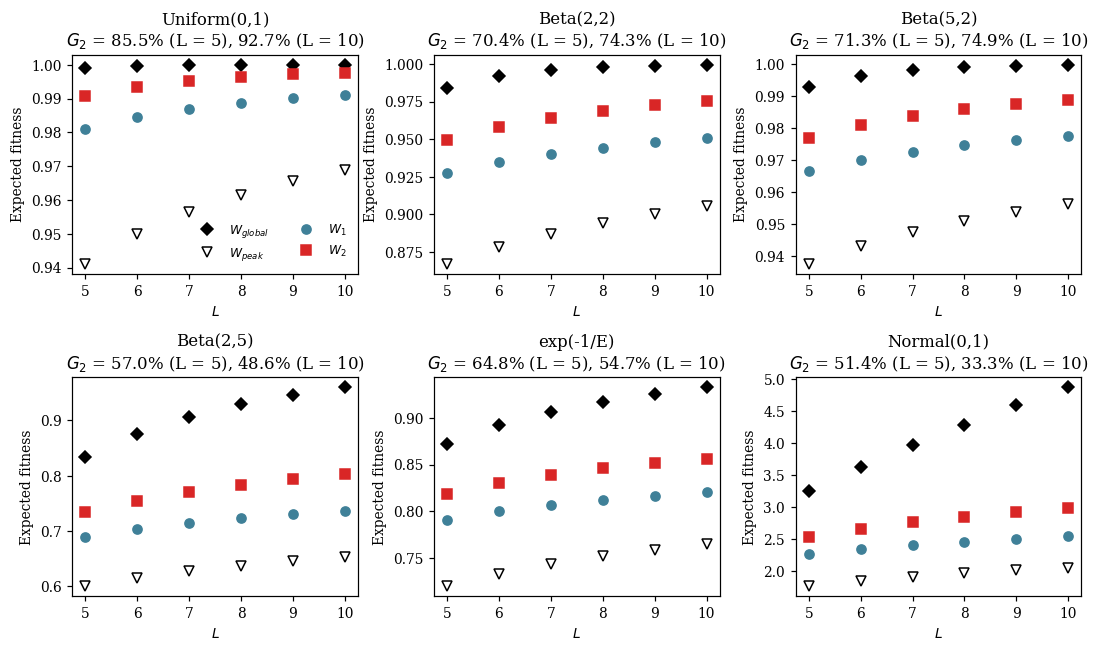

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, (name, tab) in zip(axes.flat, dist_tab.items()):
    plot_fig1c(ax, tab, title=f'{name}\n$G_2$ = {tab.G2[5]:.1%} (L = 5), {tab.G2[10]:.1%} (L = 10)')
axes.flat[0].legend(ncol=2, frameon=False, loc='lower right', fontsize=8)
plt.tight_layout()

G1                                                          \
L               5      6      7      8      9      10     12     15     20    
distribution                                                                  
Uniform(0,1)  0.691  0.696  0.702  0.708  0.713  0.717  0.723  0.728  0.734   
Beta(2,2)     0.515  0.495  0.486  0.483  0.482  0.483  0.485  0.489  0.493   
Beta(5,2)     0.526  0.506  0.496  0.493  0.491  0.492  0.493  0.496  0.499   
Beta(2,5)     0.384  0.340  0.312  0.294  0.281  0.272  0.261  0.253  0.249   
exp(-1/E)     0.466  0.421  0.390  0.366  0.348  0.333  0.311  0.287  0.263   
Normal(0,1)   0.336  0.280  0.242  0.213  0.192  0.175  0.149  0.123  0.098   

                     ...     G2                                            \
L               30   ...    9      10     12     15     20     30     50    
distribution         ...                                                    
Uniform(0,1)  0.739  ...  0.918  0.927  0.940  0.953  0.965  0.977  0.986   
Beta(2,2)     0.496  ...  0.731  0.743  0.764  0.789  0.818  0.852  0.885   
Beta(5,2)     0.501  ...  0.738  0.749  0.769  0.793  0.821  0.854  0.887   
Beta(2,5)     0.248  ...  0.490  0.486  0.484  0.491  0.511  0.546  0.590   
exp(-1/E)     0.236  ...  0.558  0.547  0.530  0.513  0.496  0.479  0.466   
Normal(0,1)   0.071  ...  0.355  0.333  0.299  0.263  0.224  0.180  0.138   

                                   
L               100    200    500  
distribution                       
Uniform(0,1)  0.993  0.997  0.999  
Beta(2,2)     0.919  0.943  0.964  
Beta(5,2)     0.920  0.943  0.964  
Beta(2,5)     0.642  0.688  0.740  
exp(-1/E)     0.457  0.454  0.454  
Normal(0,1)   0.098  0.070  0.045  

[6 rows x 28 columns]

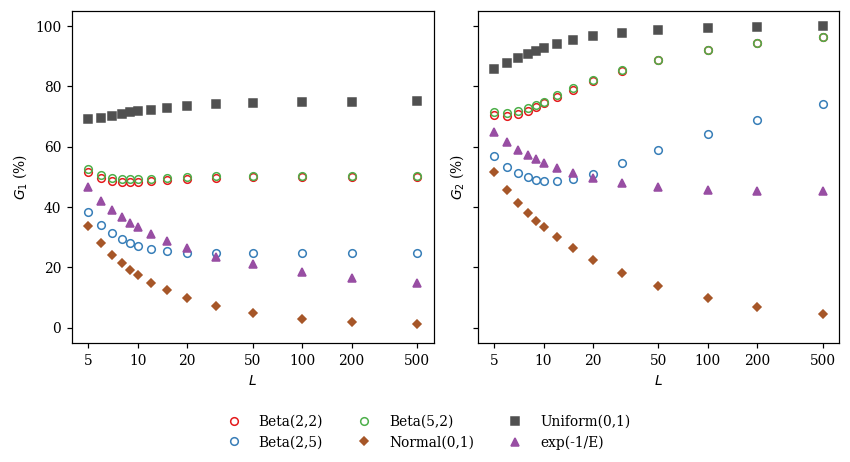

In [6]:
# G1 and G2 as functions of L, from L = 5 to 500
Lg = list(range(5, 11)) + [12, 15, 20, 30, 50, 100, 200, 500]
with warnings.catch_warnings():   # scipy's Beta isf warns at tail probabilities < 1e-300 (L = 500); values unaffected
    warnings.simplefilter('ignore', RuntimeWarning)
    G_long = pd.concat({name: analytic_table(d, Lg)[['G1', 'G2']] for name, d in DISTS.items()}, names=['distribution'])

STYLE = {  # marker, colour, filled
    'Beta(2,2)': ('o', '#E41A1C', False), 'Beta(2,5)': ('o', '#377EB8', False), 'Beta(5,2)': ('o', '#4DAF4A', False),
    'exp(-1/E)': ('^', '#984EA3', True), 'Normal(0,1)': ('D', '#A65628', True), 'Uniform(0,1)': ('s', '#505050', True),
}
fig, axes = plt.subplots(1, 2, figsize=(7.8, 4.2), sharey=True)
for ax, g in zip(axes, ['G1', 'G2']):
    for name in sorted(DISTS):
        m, c, filled = STYLE[name]
        s = G_long.loc[name, g]
        ax.plot(s.index, 100 * s, m, ls='none', ms=5 if m != 'D' else 4, mec=c, mfc=c if filled else 'none', label=name)
    ax.set_xscale('log'); ax.set_xticks([5, 10, 20, 50, 100, 200, 500], ['5', '10', '20', '50', '100', '200', '500'])
    ax.minorticks_off(); ax.set_ylim(-5, 105); ax.set_xlabel('$L$'); ax.set_ylabel(f'${g[0]}_{g[1]}$ (%)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1))
G_long.unstack('L').round(3)

## 3. Adaptive walks on a HoC landscape with $L = 9$ (Fig. 1d–f, h, i)

Walks follow the Methods. From each of 3,000 starting genotypes, one walk of each class is simulated:

* **SNM**: SNMs only.
* **adjacent MNM**: 97% SNMs and 3% adjacent MNMs.
* **general MNM**: 97% SNMs and 3% general MNMs.

Each walk accepts random beneficial mutations (SSWM) until no mutation of the allowed classes increases fitness. A peak is a genotype fitter than all its single-mutant neighbours.

In [7]:
L = 9
DATA = os.environ.get('MNM_DATA')
land_file = DATA and os.path.join(DATA, '01_HouseCard', f'seq_{L}bp.txt')
TRAJ = {'snm': ('SNM', '_adaptive_walk_by_SNM_allsites_3k_trajectory.txt'),
        'adj': ('MNM', '_adaptive_walk_by_MNM_adjacent_allsites_3k_trajectory.txt'),
        'gen': ('MNM2site', '_adaptive_walk_by_MNM2sites_allsites_3k_trajectory.txt')}
traj_file = lambda cls: os.path.join(DATA, '01_HouseCard', TRAJ[cls][0], f'seq_{L}bp' + TRAJ[cls][1])

if land_file and os.path.exists(land_file):
    SOURCE = 'archived'      # original landscape and adaptive walks of the paper
    ls = load_table(land_file, f'HoC L = {L}')
else:
    SOURCE = 'simulated'     # new HoC landscape: i.i.d. U(0,1) fitness for all 4^L genotypes
    rng = np.random.RandomState(2026)
    seqs = [''.join(s) for s in itertools.product('ACGT', repeat=L)]
    ls = Landscape(seqs, rng.uniform(0, 1, len(seqs)), f'HoC L = {L}', alphabet='ACGT')

peaks = ls.snm_peaks()
is_peak = np.zeros(ls.size, dtype=bool); is_peak[peaks] = True
print(f'{SOURCE}: {len(ls.codes):,} genotypes, {len(peaks):,} peaks '
      f'(expected 4^L/(3L+1) = {4**L / (3*L + 1):,.0f})')

simulated: 262,144 genotypes, 9,277 peaks (expected 4^L/(3L+1) = 9,362)


In [8]:
def archived_paths(cls):
    t = pd.read_table(traj_file(cls), usecols=['mutant_step', 'seq_info', 'start_sequence'])
    t = t.sort_values(['start_sequence', 'mutant_step'], kind='mergesort')
    t['code'] = [ls.encode(s) for s in t.seq_info]
    return {ls.encode(s): w.code.tolist() for s, w in t.groupby('start_sequence', sort=False)}

if SOURCE == 'archived':
    paths = {cls: archived_paths(cls) for cls in CLS}
    starts = list(paths['snm'])
else:
    starts = list(np.random.RandomState(1).choice(ls.codes, 3000, replace=False))
    paths = {}
    for j, cls in enumerate(CLS):
        rng = np.random.RandomState(10 + j)
        kind = None if cls == 'snm' else cls
        paths[cls] = {s: walk_original(ls, s, kind, p=0.03, rng=rng) for s in starts}

rows = []
for cls in CLS:
    for s in starts:
        path = np.asarray(paths[cls][s])
        f = ls.F[path]
        n = len(path) - 1
        rows.append(dict(cls=cls, start=s, n_steps=n, start_fit=f[0], end_fit=f[-1],
                         step=(f[-1] - f[0]) / n if n else np.nan,
                         n_escapes=int(is_peak[path[:-1]].sum()),        # steps that leave a peak
                         start_code=path[0], end_code=path[-1]))
walks = pd.DataFrame(rows)
walks.head()

,cls,start,n_steps,start_fit,end_fit,step,n_escapes,start_code,end_code
0,snm,246668,4,0.648547,0.976129,0.081895,0,246668,254862
1,snm,125118,4,0.402596,0.995851,0.148314,0,125118,239805
2,snm,112104,2,0.395646,0.950315,0.277335,0,112104,108010
3,snm,173805,1,0.942359,0.997304,0.054945,0,173805,177901
4,snm,94566,1,0.673286,0.847843,0.174556,0,94566,110950


In [9]:
# helpers shared by the panels below
wide_of = lambda w, v: w.pivot(index='start', columns='cls', values=v)
PAIRS = [('snm', 'adj'), ('snm', 'gen'), ('adj', 'gen')]

def boxes(ax, data, ylabel, ylim=None):
    bp = ax.boxplot([data[c].dropna() for c in CLS], widths=0.55, showfliers=False, patch_artist=True,
                    medianprops=dict(color='#333333'))
    for patch, c in zip(bp['boxes'], CLS):
        patch.set_facecolor(FILL[c]); patch.set_edgecolor('#555555')
    ax.set_xticks([1, 2, 3], [TICK[c] for c in CLS]); ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)

def panel_title(ax, letter):
    ax.set_title(f'HoC landscape of {L} sites', fontsize=9, fontweight='bold', backgroundcolor='#D9D9D9')
    ax.text(-0.2, 1.08, letter, transform=ax.transAxes, fontsize=13, fontweight='bold')

def describe(walks, v):
    # per walk class: n, mean, quartiles
    g = walks.groupby('cls', sort=False)[v]
    t = pd.DataFrame({'n': g.count(), 'mean': g.mean(), 'Q1': g.quantile(0.25), 'median': g.median(),
                      'Q3': g.quantile(0.75)})
    return t.rename(index=LAB)

def paired_wilcoxon(walks, v, pairs=PAIRS):
    w = wide_of(walks, v)
    rows = []
    for a, b in pairs:
        x = w[[a, b]].dropna()
        rows.append(dict(comparison=f'{LAB[a]} vs {LAB[b]}', n_pairs=len(x), P=stats.wilcoxon(x[a], x[b]).pvalue))
    return pd.DataFrame(rows)

def box_panel(walks, v, ylabel, letter):
    fig, ax = plt.subplots(figsize=(3.6, 3.4))
    boxes(ax, wide_of(walks, v), ylabel); panel_title(ax, letter)
    plt.tight_layout(); plt.show()
    display(describe(walks, v).round(4), paired_wilcoxon(walks, v))

### Fig. 1d: fitness at the endpoints of adaptive walks

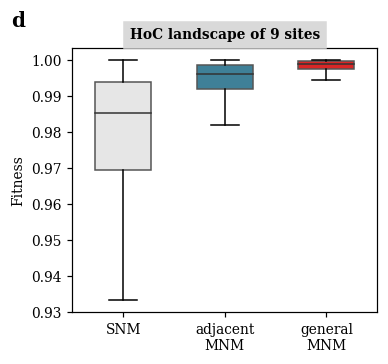

,n,mean,Q1,median,Q3
cls,,,,,
SNM,3000,0.9768,0.9694,0.9852,0.9938
adjacent MNM,3000,0.9939,0.9917,0.9960,0.9984
general MNM,3000,0.9982,0.9974,0.9988,0.9995


,comparison,n_pairs,P
0,SNM vs adjacent MNM,3000,1.709469e-281
1,SNM vs general MNM,3000,0.000000e+00
2,adjacent MNM vs general MNM,3000,1.619096e-244


In [ ]:
box_panel(walks, 'end_fit', 'Fitness', 'd')

### Fig. 1e: number of accepted mutations per walk

An accepted MNM counts as one accepted mutation.

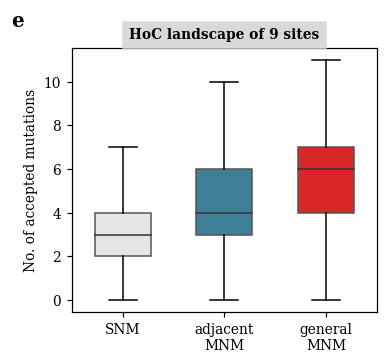

,n,mean,Q1,median,Q3
cls,,,,,
SNM,3000,3.3453,2.0,3.0,4.0
adjacent MNM,3000,4.6653,3.0,4.0,6.0
general MNM,3000,5.9177,4.0,6.0,7.0


,comparison,n_pairs,P
0,SNM vs adjacent MNM,3000,2.092841e-154
1,SNM vs general MNM,3000,0.000000e+00
2,adjacent MNM vs general MNM,3000,1.526223e-107


In [11]:
box_panel(walks, 'n_steps', 'No. of accepted mutations', 'e')

### Fig. 1f: mean fitness gain per accepted mutation

Mean step size = (endpoint fitness − starting fitness) / number of accepted mutations. Walks that start at a genotype they cannot leave (no accepted mutation) have no step size and are excluded.

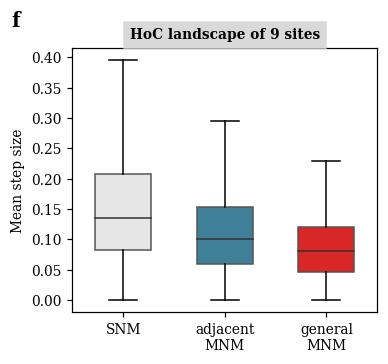

,n,mean,Q1,median,Q3
cls,,,,,
SNM,2886,0.1661,0.0825,0.1357,0.2080
adjacent MNM,2962,0.1190,0.0593,0.1012,0.1538
general MNM,2989,0.0919,0.0462,0.0811,0.1197


,comparison,n_pairs,P
0,SNM vs adjacent MNM,2886,4.111505e-95
1,SNM vs general MNM,2886,3.481367e-255
2,adjacent MNM vs general MNM,2962,1.545706e-79


In [12]:
box_panel(walks, 'step', 'Mean step size', 'f')

### Fig. 1h: number of peaks escaped per walk

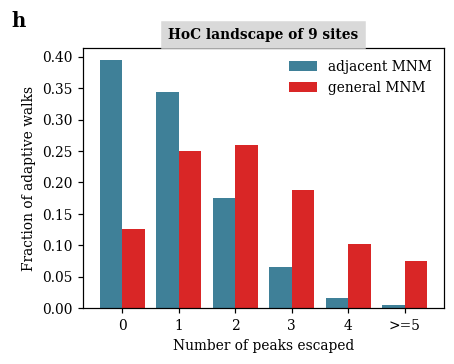

peaks escaped,0,1,2,3,4,>=5
adjacent MNM,0.3947,0.3433,0.175,0.065,0.0167,0.0053
general MNM,0.1263,0.2493,0.259,0.188,0.1027,0.0747


,n,mean,Q1,median,Q3
cls,,,,,
adjacent MNM,3000,0.983,0.0,1.0,2.0
general MNM,3000,2.148,1.0,2.0,3.0


,comparison,n_pairs,P
0,adjacent MNM vs general MNM,3000,3.352499e-199


In [13]:
cats = ['0', '1', '2', '3', '4', '>=5']
dist_esc = pd.DataFrame({LAB[c]: walks.loc[walks.cls == c, 'n_escapes'].clip(upper=5)
                                     .value_counts(normalize=True).reindex(range(6), fill_value=0).values
                         for c in ['adj', 'gen']}, index=pd.Index(cats, name='peaks escaped'))

fig, ax = plt.subplots(figsize=(4.2, 3.4))
for cls, dx in [('adj', -0.2), ('gen', 0.2)]:
    ax.bar(np.arange(6) + dx, dist_esc[LAB[cls]], 0.4, color=FILL[cls], label=LAB[cls])
ax.set_xticks(range(6), cats); ax.set_xlabel('Number of peaks escaped')
ax.set_ylabel('Fraction of adaptive walks'); ax.legend(frameon=False); panel_title(ax, 'h')
plt.tight_layout(); plt.show()

display(dist_esc.T.round(4), describe(walks[walks.cls != 'snm'], 'n_escapes').round(3),
        paired_wilcoxon(walks, 'n_escapes', pairs=[('adj', 'gen')]))

### Fig. 1i: fraction of peaks escapable by MNMs

A peak is escapable if at least one adjacent (or general) MNM from it increases fitness. Peaks are ranked by fitness and divided into 10 bins with the same number of peaks; error bars are binomial standard errors.

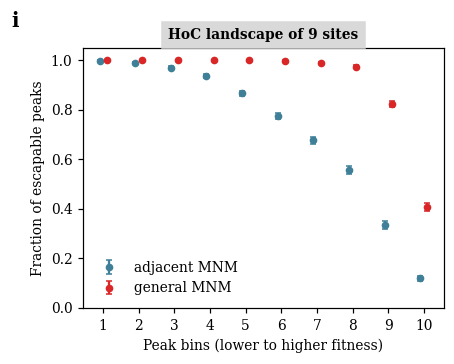

bin,1,2,3,4,5,6,7,8,9,10
kind,,,,,,,,,,
adjacent MNM,0.998,0.987,0.97,0.936,0.865,0.775,0.676,0.556,0.334,0.120
general MNM,1.000,1.000,1.00,1.000,1.000,0.998,0.990,0.973,0.822,0.409


In [14]:
order = peaks[np.argsort(ls.F[peaks], kind='mergesort')]
bins = np.array_split(order, 10)
esc_bins = pd.DataFrame([dict(bin=i + 1, kind=kind, n=len(b),
                              frac=np.mean([len(ls.beneficial(int(c), kind)) > 0 for c in b]))
                         for i, b in enumerate(bins) for kind in ['adj', 'gen']])
esc_bins['se'] = np.sqrt(esc_bins.frac * (1 - esc_bins.frac) / esc_bins.n)

fig, ax = plt.subplots(figsize=(4.2, 3.4))
for kind, dx in [('adj', -0.1), ('gen', 0.1)]:
    d = esc_bins[esc_bins.kind == kind]
    ax.errorbar(d.bin + dx, d.frac, d.se, fmt='o', ms=4, color=FILL[kind], capsize=2, label=LAB[kind])
ax.set_xticks(range(1, 11)); ax.set_xlabel('Peak bins (lower to higher fitness)')
ax.set_ylabel('Fraction of escapable peaks'); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc='lower left'); panel_title(ax, 'i')
plt.tight_layout(); plt.show()

esc_bins.assign(kind=esc_bins.kind.map(LAB)).pivot(index='kind', columns='bin', values='frac').round(3)

## 4. $L = 9$ adaptation metrics under other fitness distributions

Under SSWM, a walk accepts any mutation that increases fitness. The trajectories therefore depend only on the fitness **ranks** of the genotypes, and a HoC landscape with any continuous i.i.d. fitness distribution is the uniform landscape above with each fitness replaced by $Q(u)$, where $u$ is the genotype's rank quantile.

So the walks of part 3 can be re-scored under each distribution:

* **Unchanged:** the number of accepted mutations (e), the number of peaks escaped (h), and the escapable peaks (i).
* **Changed:** endpoint fitness (d), mean step size (f), and the fraction of the fitness gap closed by MNMs.

To compare distributions, endpoint fitness is also given in standard-deviation units, $(w - \mu)/\sigma$.

In [15]:
N = len(ls.codes)
rank_q = np.full(ls.size, np.nan)
rank_q[ls.codes[np.argsort(ls.F[ls.codes], kind='mergesort')]] = (np.arange(N) + 0.5) / N   # rank quantile of every genotype

rescored, rows = {}, []
for name, d in DISTS.items():
    Fq = d.ppf(rank_q)                       # fitness of every genotype under this distribution
    mu, sd = d.mean(), d.std()
    w = walks.copy()
    w['end_fit'] = Fq[w.end_code]
    w['start_fit'] = Fq[w.start_code]
    w['step'] = np.where(w.n_steps > 0, (w.end_fit - w.start_fit) / w.n_steps.replace(0, 1), np.nan)
    w['end_z'] = (w.end_fit - mu) / sd
    rescored[name] = w
    m = w.groupby('cls').end_fit.mean()
    G = lambda c: (m[c] - m['snm']) / (Fq[ls.codes].max() - m['snm'])
    for cls in CLS:
        x = w[w.cls == cls]
        rows.append(dict(distribution=name, cls=LAB[cls], mean_end_fit=x.end_fit.mean(), mean_end_z=x.end_z.mean(),
                         median_step=x.step.median(), gain_over_SNM_z=x.end_z.mean() - w[w.cls == 'snm'].end_z.mean(),
                         gap_closed=G(cls) if cls != 'snm' else np.nan))
dist_walks = pd.DataFrame(rows)
dist_walks.pivot(index='distribution', columns='cls').round(4).loc[list(DISTS)]

mean_end_fit                          mean_end_z               \
cls                   SNM adjacent MNM general MNM        SNM adjacent MNM   
distribution                                                                 
Uniform(0,1)       0.9769       0.9938      0.9981     1.6519       1.7107   
Beta(2,2)          0.9204       0.9594      0.9777     1.8802       2.0547   
Beta(5,2)          0.9633       0.9816      0.9899     1.5593       1.6736   
Beta(2,5)          0.6799       0.7578      0.8109     2.4677       2.9557   
exp(-1/E)          0.7828       0.8325      0.8608     2.0300       2.2304   
Normal(0,1)        2.2074       2.6836      3.0610     2.2074       2.6836   

                         median_step                          gain_over_SNM_z  \
cls          general MNM         SNM adjacent MNM general MNM             SNM   
distribution                                                                    
Uniform(0,1)      1.7255      0.1359       0.1013      0.0812             0.0   
Beta(2,2)         2.1363      0.1222       0.0952      0.0795             0.0   
Beta(5,2)         1.7259      0.0680       0.0531      0.0435             0.0   
Beta(2,5)         3.2883      0.1178       0.1022      0.0897             0.0   
exp(-1/E)         2.3446      0.1492       0.1177      0.0987             0.0   
Normal(0,1)       3.0610      0.6454       0.5751      0.5165             0.0   

                                      gap_closed                           
cls          adjacent MNM general MNM        SNM adjacent MNM general MNM  
distribution                                                               
Uniform(0,1)       0.0588      0.0736        NaN       0.7337      0.9187  
Beta(2,2)          0.1745      0.2561        NaN       0.4952      0.7270  
Beta(5,2)          0.1143      0.1666        NaN       0.5029      0.7329  
Beta(2,5)          0.4880      0.8206        NaN       0.2892      0.4863  
exp(-1/E)          0.2003      0.3145        NaN       0.3447      0.5412  
Normal(0,1)        0.4762      0.8535        NaN       0.1973      0.3536

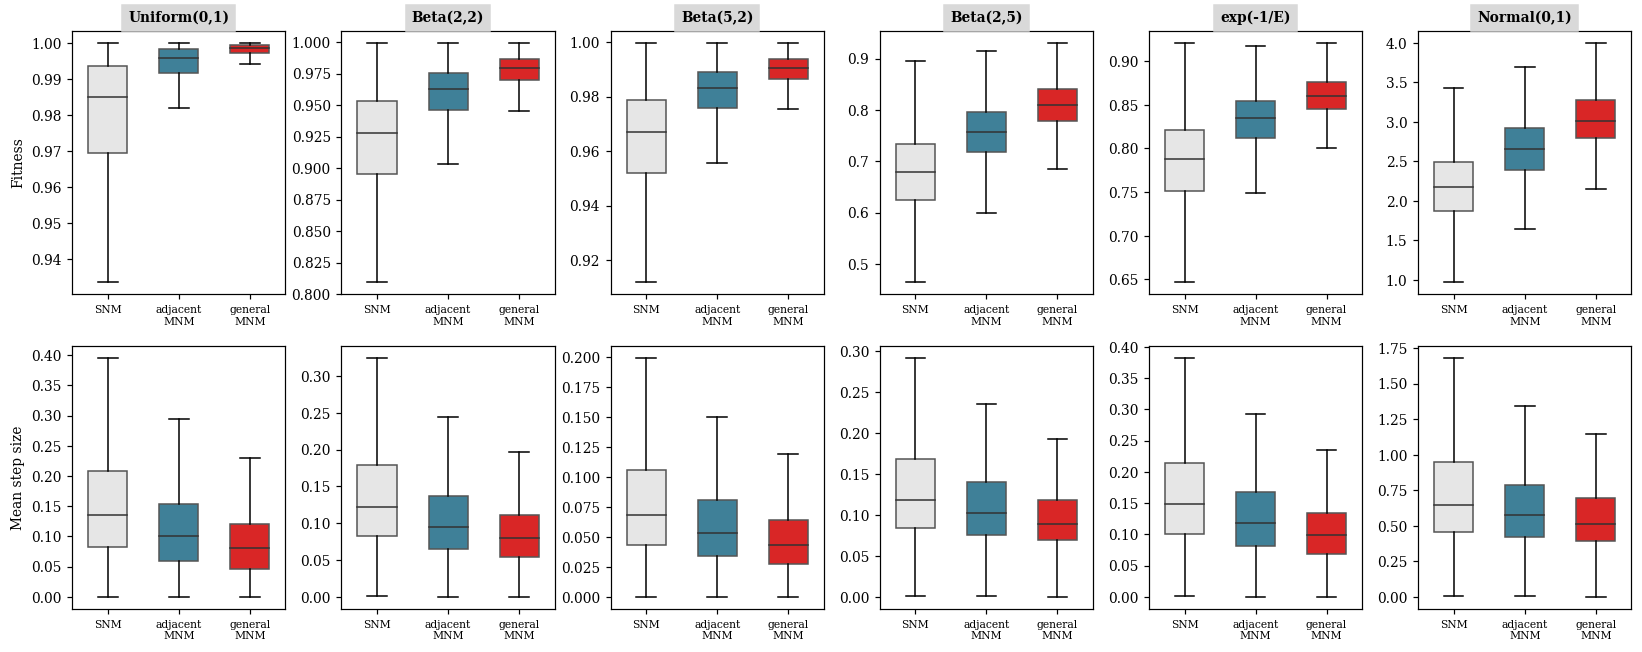

In [16]:
# Fig. 1d (endpoint fitness) and 1f (mean step size) under each distribution
fig, axes = plt.subplots(2, len(DISTS), figsize=(15, 6))
for j, (name, w) in enumerate(rescored.items()):
    boxes(axes[0, j], wide_of(w, 'end_fit'), 'Fitness' if j == 0 else '')
    boxes(axes[1, j], wide_of(w, 'step'), 'Mean step size' if j == 0 else '')
    axes[0, j].set_title(name, fontsize=9, fontweight='bold', backgroundcolor='#D9D9D9')
    for ax in axes[:, j]:
        ax.tick_params(axis='x', labelsize=7)
plt.tight_layout()

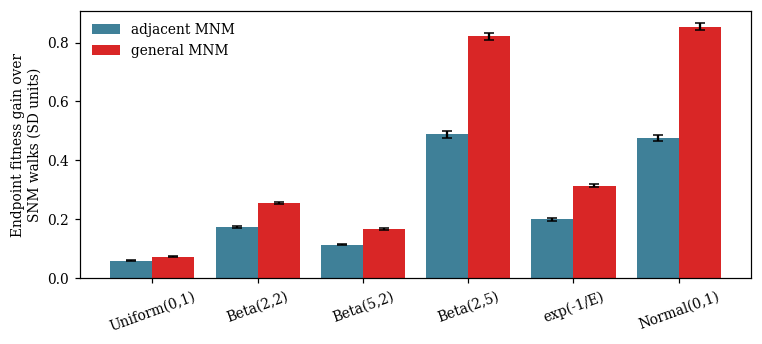

In [17]:
# gain of MNM walks over SNM walks (same starts), in standard deviations of the fitness distribution
gain = pd.concat({name: (wide_of(w, 'end_z')[['adj', 'gen']].sub(wide_of(w, 'end_z')['snm'], axis=0))
                  for name, w in rescored.items()}, names=['distribution'])
fig, ax = plt.subplots(figsize=(7, 3.2))
m = gain.groupby('distribution').mean().loc[list(DISTS)]
s = gain.groupby('distribution').sem().loc[list(DISTS)]
x = np.arange(len(DISTS))
for cls, dx in [('adj', -0.2), ('gen', 0.2)]:
    ax.bar(x + dx, m[cls], 0.4, yerr=s[cls], color=FILL[cls], capsize=3, label=LAB[cls])
ax.set_xticks(x, list(DISTS), rotation=20)
ax.set_ylabel('Endpoint fitness gain over\nSNM walks (SD units)'); ax.legend(frameon=False)
plt.tight_layout()